# The top-k read, three ways

In the labelled read, every patch of every photo reads labels from the patches of the context photos, and with `patch_read = "top_k"` only from the `top_k` context photos nearest to its own. The trained runs use `top_k = 32`. The code that runs today does this by gathering, for each reading photo, a private copy of its 32 neighbours' patches as its keys. This notebook writes the same read in two other ways, as one attention over every context patch with a mask, dense and then block-sparse, and checks on the same weights and inputs that all three give the same numbers, forwards and backwards. The point is that the gather is an implementation choice, and the memory it costs in training is not inherent to the idea.

The setting is the trained one, `top_k = 32`, on 64 context photos and 16 test photos with 4 patches each at width 16, so it runs on a CPU in a second. The read's weights are random: the equality is between functions, not trained models.

In [1]:
import os, sys, inspect, warnings
os.chdir(next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.exists(os.path.join(p, "table_image_icl"))))
sys.path.insert(0, os.getcwd())
import torch
import matplotlib.pyplot as plt
from table_image_icl.reading import LabelRead, nearest_photos, neighbour_mask
torch.manual_seed(0); torch.set_printoptions(precision=3, sci_mode=False, linewidth=120)

def show(*objects):
    for o in objects:
        print(inspect.getsource(o))

TOP_K = 32                                                          # the trained setting
D, HEADS, N_CONTEXT, N_TEST, PATCHES = 16, 2, 64, 16, 4
read = LabelRead(D, HEADS).eval()
tokens = torch.randn(1, N_CONTEXT + N_TEST, PATCHES, D)          # (batch, photos, patches, width), context photos first
sources = tokens[:, :N_CONTEXT]                                     # the context photos are the sources
labels = torch.randn(1, N_CONTEXT, D)                               # one label embedding per context photo: the values
nearest = nearest_photos(tokens, sources, TOP_K)                    # (batch, photos, top_k)
print("tokens", tuple(tokens.shape), "| sources", tuple(sources.shape), "| nearest", tuple(nearest.shape))
print("photo 70 reads from context photos", sorted(nearest[0, 70].tolist()))

tokens (1, 80, 4, 16) | sources (1, 64, 4, 16) | nearest (1, 80, 32)
photo 70 reads from context photos [2, 3, 6, 10, 11, 12, 13, 14, 17, 18, 20, 22, 23, 26, 28, 29, 30, 31, 34, 36, 38, 40, 46, 47, 48, 50, 52, 53, 57, 58, 62, 63]


## 1. The gather: what runs today

`LabelRead.forward` with `nearest`: for a chunk of reading photos, the patches of their neighbours are gathered into one key tensor per reading photo, `(reading photos, top_k x patches, width)`, the neighbours' labels are repeated over their patches as the values, and the reading photo's patches attend over its own key set. Every reading photo gets its own copy of 32 x 4 = 128 keys.

In [2]:
show(LabelRead.forward)
with torch.no_grad():
    gathered = read(tokens, sources, labels, nearest)
print("read", tuple(tokens.shape), "->", tuple(gathered.shape))
print("keys per reading photo:", TOP_K * PATCHES, "| key copies held for the whole batch:", (N_CONTEXT + N_TEST) * TOP_K * PATCHES, "patch tokens")

    def forward(self, readers: Tensor, sources: Tensor, source_labels: Tensor, nearest: Tensor | None = None) -> Tensor:
        """readers (batch, photos, patches, width); sources (batch, S, patches, width); source_labels (batch, S, width).
        Without `nearest`, every patch attends to every source patch. With `nearest` (batch, photos, k), each photo
        attends only to the patches of its k neighbours. Returns what each reading patch read: the shape of readers."""
        batch, photos, patches, width = readers.shape
        queries, keys = self.norm_readers(readers), self.norm_sources(sources)
        if nearest is None:
            values = source_labels[:, :, None].expand(-1, -1, patches, -1).flatten(1, 2)
            read = self.attention(queries.flatten(1, 2), keys.flatten(1, 2), values)
            return read.reshape(batch, photos, patches, width)

        rows = torch.arange(batch, device=readers.device)[:, None, None]
        out = []
        for start in range(0, pho

## 2. The same read as a mask

Write the keys once, every patch of every context photo, `(sources x patches, width)`, and give each query a rule for which keys it may use: a key is allowed when its photo is among the query's photo's neighbours. That rule is the block mask `neighbour_mask(nearest)`, `(photos, sources)` with `top_k` True per row; expanded over patches it becomes the `(photos x patches, sources x patches)` mask of the attention. `LabelRead.forward_masked` does exactly that, with the mask materialised, through the same `Attention` module and weights.

Why it is the same function. For one query $q$ with neighbours $N$, the gather computes

$$\text{out} = \sum_{j \in N} \sum_{p} \frac{e^{q \cdot k_{jp}}}{\sum_{j' \in N} \sum_{p'} e^{q \cdot k_{j'p'}}}\, v_j,$$

and the mask computes the softmax over all context patches with the score set to $-\infty$ outside $N$. Since $e^{-\infty} = 0$, those terms vanish from both the numerator and the denominator, which leaves the expression above. Attention is a sum over keys, so the order the gather puts them in does not matter either. Same function, so same output and, by the chain rule, same gradients.

def neighbour_mask(nearest: Tensor, n_sources: int) -> Tensor:
    """nearest (batch, photos, k) -> (batch, photos, S), True where source j is among photo i's neighbours."""
    allowed = torch.zeros(*nearest.shape[:2], n_sources, dtype=torch.bool, device=nearest.device)
    return allowed.scatter(2, nearest, True)

    def forward_masked(self, readers: Tensor, sources: Tensor, source_labels: Tensor, nearest: Tensor) -> Tensor:
        """The top-k read written as one attention over every source patch, with a key allowed only when its photo is
        among the reader's neighbours. The same function as forward with `nearest`: a softmax with -inf outside the
        allowed keys is the softmax over the allowed keys. The mask is dense here, so this is a reference, not the
        way to train; a block-sparse kernel over neighbour_mask would make it the memory-cheap way."""
        batch, photos, patches, width = readers.shape
        n_sources = sources.shape[1]
        queries, keys = s

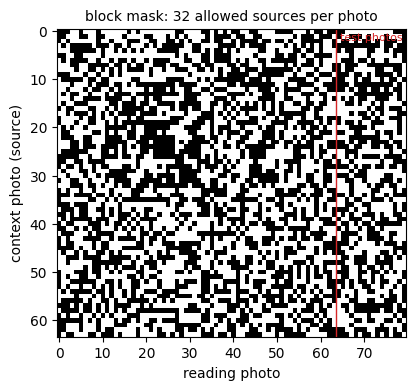

In [3]:
show(neighbour_mask, LabelRead.forward_masked)
allowed = neighbour_mask(nearest, N_CONTEXT)                       # (batch, photos, sources)
with torch.no_grad():
    masked = read.forward_masked(tokens, sources, labels, nearest)
print("block mask", tuple(allowed.shape), "| allowed sources per photo:", allowed[0].sum(-1).unique().tolist())
print("dense attention mask:", (N_CONTEXT + N_TEST) * PATCHES, "x", N_CONTEXT * PATCHES, "| block mask:", N_CONTEXT + N_TEST, "x", N_CONTEXT)
print("max |gather - mask| over every output value:", (gathered - masked).abs().max().item())
print("identical to float precision:", torch.allclose(gathered, masked, atol=1e-5))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(allowed[0].T, cmap="Greys", aspect="auto", interpolation="nearest")
ax.axvline(N_CONTEXT - 0.5, color="C3", lw=1); ax.text(N_CONTEXT + 0.5, 2, "test photos", color="C3", fontsize=8)
ax.set_xlabel("reading photo"); ax.set_ylabel("context photo (source)"); ax.set_title(f"block mask: {TOP_K} allowed sources per photo", fontsize=10)
plt.show()

The diagonal of the context part is filled: each context photo is its own nearest and reads its own label among the others.

Gradients too. The loss below is arbitrary; what matters is that its gradient with respect to the input tokens, and with respect to the read's weights, agrees between the two ways.

In [4]:
x = tokens.clone().requires_grad_(True)
grads = {}
for name, fn in [("gather", read.forward), ("mask", read.forward_masked)]:
    read.zero_grad()
    out = fn(x, x[:, :N_CONTEXT], labels, nearest)
    out.square().sum().backward()
    grads[name] = (x.grad.clone(), [p.grad.clone() for p in read.parameters()])
    x.grad = None
print("max |gather - mask| in the gradient w.r.t. the tokens:", (grads["gather"][0] - grads["mask"][0]).abs().max().item())
print("max |gather - mask| in the gradients w.r.t. the weights:", max((a - b).abs().max().item() for a, b in zip(grads["gather"][1], grads["mask"][1])))

max |gather - mask| in the gradient w.r.t. the tokens: 2.2351741790771484e-08
max |gather - mask| in the gradients w.r.t. the weights: 2.09808349609375e-05


## 3. The block-sparse kernel

The dense mask is the reference, not the way to run it: at training size it is `(256 x 256) x (230 x 256)`, about 3.9 billion entries per task. The block mask is `256 x 230`. PyTorch's `flex_attention` takes the mask as a function of the query and key indices, evaluates it inside the attention kernel tile by tile, and never stores the dense form; the keys and values are projected once for the whole context. That is attention with the memory of reading everything and the retrieval of top-k. Measured on an A100 at the training batch of 1,024 photos, the gather peaks at 27 GB at `top_k = 32` and does not fit at 64, while reading everything peaks at 11.5 GB.

The same function once more, through that kernel, with the mask written as a rule on indices. On a CPU without `torch.compile` it runs unfused and its backward is not supported, so this cell is forward only; on a GPU, compiled, it is the fused kernel. The kernel skips a 128-key block only when every key in it is masked: at training size a context photo is 256 keys, two whole blocks, so every neighbour not retrieved is a block skipped; in this toy a block holds 32 photos and nothing is skipped, which is fine for checking the function and says nothing about speed.

In [5]:
from torch.nn.attention.flex_attention import flex_attention, create_block_mask
warnings.filterwarnings("ignore", message="flex_attention called without torch.compile")

def allowed_key(b, h, q, kv):                                       # the block mask as a rule on a query index and a key index
    return allowed[b, q // PATCHES, kv // PATCHES]

a = read.attention
with torch.no_grad():
    queries, keys = read.norm_readers(tokens).flatten(1, 2), read.norm_sources(sources).flatten(1, 2)
    values = labels[:, :, None].expand(-1, -1, PATCHES, -1).flatten(1, 2)
    q, k, v = a.split(a.q(queries)), a.split(a.k(keys)), a.split(a.v(values))     # projected once for the whole context
    block = create_block_mask(allowed_key, 1, None, queries.shape[1], keys.shape[1], device="cpu")
    out = flex_attention(q, k, v, block_mask=block)
    sparse = a.o(out.transpose(1, 2).flatten(-2)).reshape(tokens.shape)
print("max |gather - flex| over every output value:", (gathered - sparse).abs().max().item())
print("identical to float precision:", torch.allclose(gathered, sparse, atol=1e-5))

max |gather - flex| over every output value: 1.1920928955078125e-07
identical to float precision: True


## 4. What this buys, and what is not done

Three implementations, one function: the gather we train with, a dense mask, and a block-sparse kernel, agree to float precision in outputs and gradients at `top_k = 32`. With the block-sparse kernel the top-k read would cost what reading everything costs, independent of `top_k`, so `top_k` could grow to the whole context at the training batch.

Not done: making `flex_attention` the training path. That needs the compiled kernel on a GPU, a check that its outputs and gradients match the gather as they do here, and a timing, since the fused kernel's speed depends on how the 32 neighbours scatter over the key blocks.